# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Fio Octriyanti
- **Email:** ds284b6x0623@student.devacademy.id
- **ID Dicoding:** DS284B6X0623


## Menentukan Pertanyaan Bisnis

Analisis ini menggunakan E-Commerce Public Dataset dari Olist. Fokus analisis adalah tren transaksi dan performa pengiriman untuk mendukung evaluasi operasional e-commerce.

**Pertanyaan 1 : Tren transaksi bulanan**

Bagaimana perubahan jumlah pesanan unik dan total nilai produk per bulan selama periode September 2016–Oktober 2018, serta pada bulan mana masing-masing metrik mencapai nilai tertinggi dan terendah?

**Pertanyaan 2 : Ketepatan pengiriman dan ulasan pelanggan**

Selama periode September 2016–Oktober 2018, bagaimana perbedaan rata-rata skor ulasan antara pesanan yang terlambat dan pesanan yang tiba tepat waktu atau lebih cepat, serta negara bagian mana yang memiliki tingkat keterlambatan tertinggi di antara wilayah dengan minimal 100 pesanan yang memiliki data pengiriman lengkap?


## 1. Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Data Wrangling
### Gathering Data

In [2]:
# Memuat dataset yang dibutuhkan
orders_df = pd.read_csv("data/orders_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")

# Membaca ulasan dengan melewati baris yang rusak akibat masalah tanda kutip/format data
order_reviews_df = pd.read_csv("data/order_reviews_dataset.csv", on_bad_lines='skip')

customers_df = pd.read_csv("data/customers_dataset.csv")
geolocation_df = pd.read_csv("data/geolocation_dataset.csv")

### Assessing Data

In [3]:
# Membuat dictionary berisi seluruh dataset yang telah dimuat
datasets = {
    "Orders": orders_df,
    "Order Items": order_items_df,
    "Reviews": order_reviews_df,
    "Customers": customers_df,
    "Geolocation": geolocation_df
}

# Melakukan pengecekan secara menyeluruh menggunakan loop
for name, df in datasets.items():
    print(f"=== ASSESSING DATASET: {name} ===")
    print(f"Shape: {df.shape}")
    print("\n--- Info & Tipe Data ---")
    df.info()

    print("\n--- Jumlah Missing Values ---")
    missing_count = df.isna().sum()
    print(missing_count[missing_count > 0] if missing_count.sum() > 0 else "Tidak ada missing values.")

    print("\n--- Jumlah Duplikasi ---")
    print(f"Duplicated rows: {df.duplicated().sum()}")

    print("\n--- Statistik Deskriptif Ringkas ---")
    display(df.describe(include='all'))
    print("="*50 + "\n")

=== ASSESSING DATASET: Orders ===
Shape: (99441, 8)

--- Info & Tipe Data ---
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

--- Jumlah Missing Values ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

--- Jumlah Duplikasi ---
Duplicated rows: 0

--- 

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522



=== ASSESSING DATASET: Order Items ===
Shape: (112650, 7)

--- Info & Tipe Data ---
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB

--- Jumlah Missing Values ---
Tidak ada missing values.

--- Jumlah Duplikasi ---
Duplicated rows: 0

--- Statistik Deskriptif Ringkas ---


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
count,112650,112650.000000,112650,112650,112650,112650.000000,112650.000000
unique,98666,NaN,32951,3095,93318,NaN,NaN
top,8272b63d03f5f79c56e9e4120aec44ef,NaN,aca2eb7d00ea1a7b8ebd4e68314663af,6560211a19b47992c3666cc44a7e94c0,2018-03-01 02:50:48,NaN,NaN
freq,21,NaN,527,2033,21,NaN,NaN
mean,NaN,1.197834,NaN,NaN,NaN,120.653739,19.990320
std,NaN,0.705124,NaN,NaN,NaN,183.633928,15.806405
min,NaN,1.000000,NaN,NaN,NaN,0.850000,0.000000
25%,NaN,1.000000,NaN,NaN,NaN,39.900000,13.080000
50%,NaN,1.000000,NaN,NaN,NaN,74.990000,16.260000
75%,NaN,1.000000,NaN,NaN,NaN,134.900000,21.150000



=== ASSESSING DATASET: Reviews ===
Shape: (99224, 7)

--- Info & Tipe Data ---
<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB

--- Jumlah Missing Values ---
review_comment_title      87656
review_comment_message    58247
dtype: int64

--- Jumlah Duplikasi ---
Duplicated rows: 0

--- Statistik Deskriptif Ringkas ---


...

Duplicated rows: 0

--- Statistik Deskriptif Ringkas ---


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN



=== ASSESSING DATASET: Geolocation ===
Shape: (1000163, 5)

--- Info & Tipe Data ---
<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 50.1 MB

--- Jumlah Missing Values ---
Tidak ada missing values.

--- Jumlah Duplikasi ---


Duplicated rows: 261831

--- Statistik Deskriptif Ringkas ---


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
count,1.000163e+06,1.000163e+06,1.000163e+06,1000163,1000163
unique,NaN,NaN,NaN,8011,27
top,NaN,NaN,NaN,sao paulo,SP
freq,NaN,NaN,NaN,135800,404268
mean,3.657417e+04,-2.117615e+01,-4.639054e+01,NaN,NaN
std,3.054934e+04,5.715866e+00,4.269748e+00,NaN,NaN
min,1.001000e+03,-3.660537e+01,-1.014668e+02,NaN,NaN
25%,1.107500e+04,-2.360355e+01,-4.857317e+01,NaN,NaN
50%,2.653000e+04,-2.291938e+01,-4.663788e+01,NaN,NaN
75%,6.350400e+04,-1.997962e+01,-4.376771e+01,NaN,NaN


### Cleaning Data

In [4]:
# 1. Konversi kolom tanggal ke datetime
datetime_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Batasi seluruh transaksi pada periode analisis (Sep 2016–Okt 2018).
# Batas akhir eksklusif 1 Nov mencakup seluruh tanggal 31 Oktober.
analysis_start = pd.Timestamp('2016-09-01')
analysis_end = pd.Timestamp('2018-11-01')
orders_period_df = orders_df[
    (orders_df['order_purchase_timestamp'] >= analysis_start) &
    (orders_df['order_purchase_timestamp'] < analysis_end)
].copy()

# 3. Untuk analisis pengiriman, gunakan pesanan terkirim dengan tanggal
# aktual dan estimasi yang lengkap.
orders_clean_df = orders_period_df[
    (orders_period_df['order_status'] == 'delivered') &
    (orders_period_df['order_delivered_customer_date'].notna()) &
    (orders_period_df['order_estimated_delivery_date'].notna())
].copy()


In [5]:
# Simpan DataFrame yang sudah dibersihkan & digabung ke dalam file main_data.csv
# Sesuaikan nama dataframe dengan dataframe utama Anda (misal: merged_delivery_df atau orders_clean_df)
orders_clean_df.to_csv("dashboard/main_data.csv", index=False)
print("File main_data.csv berhasil dibuat!")

File main_data.csv berhasil dibuat!


## 3. Exploratory Data Analysis (EDA)

In [6]:
# ==========================================
# EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

print("=== 1. Eksplorasi Distribusi Nilai Review Pelanggan ===")
review_stats = order_reviews_df['review_score'].describe()
print(review_stats)
print("Distribusi skor ulasan:")
print(order_reviews_df['review_score'].value_counts(normalize=True) * 100)
print("\n" + "="*50 + "\n")

print("=== 2. Eksplorasi Hubungan Status Pengiriman dengan Rata-rata Skor Review ===")
# Bandingkan ulasan hanya pada pesanan dengan tanggal pengiriman lengkap.
orders_clean_df['is_late'] = (
    orders_clean_df['order_delivered_customer_date'] >
    orders_clean_df['order_estimated_delivery_date']
)
orders_clean_df['delivery_status'] = orders_clean_df['is_late'].map(
    {True: 'Late', False: 'On-time/Early'}
)

merged_review_df = pd.merge(orders_clean_df, order_reviews_df, on='order_id', how='inner')
delivery_review_summary = merged_review_df.groupby('delivery_status').agg(
    jumlah_pesanan=('order_id', 'nunique'),
    rata_rata_review_score=('review_score', 'mean')
).reset_index()
display(delivery_review_summary)
print("\n" + "="*50 + "\n")

print("=== 3. Eksplorasi Persebaran Pelanggan berdasarkan Negara Bagian (Top 10) ===")
customer_by_state = customers_df.groupby('customer_state').customer_id.count().sort_values(ascending=False).head(10).reset_index()
customer_by_state = customer_by_state.rename(
    columns={"customer_id": "customer_count"}
)
display(customer_by_state)
print("\n" + "="*50 + "\n")

print("=== 4. Eksplorasi Nilai Transaksi per Transaksi (Order Items) ===")
order_items_stats = order_items_df['price'].describe()
print(order_items_stats)
print("\n" + "="*50 + "\n")

# ----------------------------------------------------
# PREPARASI DATA UNTUK VISUALISASI
# ----------------------------------------------------

# Pertanyaan 1: hitung semua pesanan pada rentang tanggal, tidak hanya
# pesanan delivered. Revenue dihitung dari total harga item per pesanan.
orders_period_df['year_month'] = (
    orders_period_df['order_purchase_timestamp'].dt.to_period('M').astype(str)
)
monthly_orders = orders_period_df.groupby('year_month').agg(
    total_orders=('order_id', 'nunique')
).reset_index()

order_items_sum = order_items_df.groupby('order_id', as_index=False)['price'].sum()
monthly_items = orders_period_df[['order_id', 'year_month']].merge(
    order_items_sum, on='order_id', how='inner'
)
monthly_revenue = monthly_items.groupby('year_month', as_index=False).agg(
    total_revenue=('price', 'sum')
)

# Tampilkan seluruh bulan Sep 2016–Okt 2018, termasuk bulan tanpa pesanan.
all_months = pd.period_range('2016-09', '2018-10', freq='M').astype(str)
monthly_summary = pd.DataFrame({'year_month': all_months})
monthly_summary = monthly_summary.merge(monthly_orders, on='year_month', how='left')
monthly_summary = monthly_summary.merge(monthly_revenue, on='year_month', how='left')
monthly_summary[['total_orders', 'total_revenue']] = monthly_summary[
    ['total_orders', 'total_revenue']
].fillna(0)
monthly_summary['total_orders'] = monthly_summary['total_orders'].astype(int)

# Pertanyaan 2: kaitkan ulasan dan wilayah dengan pesanan beserta status pengirimannya.
merged_delivery_df = pd.merge(
    orders_clean_df,
    order_reviews_df[['order_id', 'review_score']],
    on='order_id', how='inner'
)
merged_delivery_df = pd.merge(
    merged_delivery_df,
    customers_df[['customer_id', 'customer_state']],
    on='customer_id', how='inner'
)
review_by_status = merged_delivery_df.groupby('delivery_status')['review_score'].mean().reset_index()

# Tingkat keterlambatan per wilayah memakai pesanan unik dengan data pengiriman lengkap.
state_delivery_df = pd.merge(
    orders_clean_df[['order_id', 'customer_id', 'is_late']],
    customers_df[['customer_id', 'customer_state']],
    on='customer_id', how='inner'
).drop_duplicates(subset='order_id')
state_summary = state_delivery_df.groupby('customer_state').agg(
    total_orders=('order_id', 'nunique'),
    late_orders=('is_late', 'sum')
).reset_index()
state_filtered = state_summary[state_summary['total_orders'] >= 100].copy()
state_filtered['late_rate'] = (
    state_filtered['late_orders'] / state_filtered['total_orders'] * 100
)
state_filtered = state_filtered.sort_values(by='late_rate', ascending=False)


=== 1. Eksplorasi Distribusi Nilai Review Pelanggan ===
count    99224.000000
mean         4.086421
std          1.347579
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64
Distribusi skor ulasan:
review_score
5    57.776344
4    19.291704
1    11.513344
3     8.242965
2     3.175643
Name: proportion, dtype: float64


=== 2. Eksplorasi Hubungan Status Pengiriman dengan Rata-rata Skor Review ===


,delivery_status,jumlah_pesanan,rata_rata_review_score
0,Late,7661,2.566494
1,On-time/Early,88163,4.293718




=== 3. Eksplorasi Persebaran Pelanggan berdasarkan Negara Bagian (Top 10) ===


,customer_state,customer_count
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020




=== 4. Eksplorasi Nilai Transaksi per Transaksi (Order Items) ===
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64




## 4. Visualization & Explanatory Analysis

### Pertanyaan 1: Tren Transaksi Bulanan

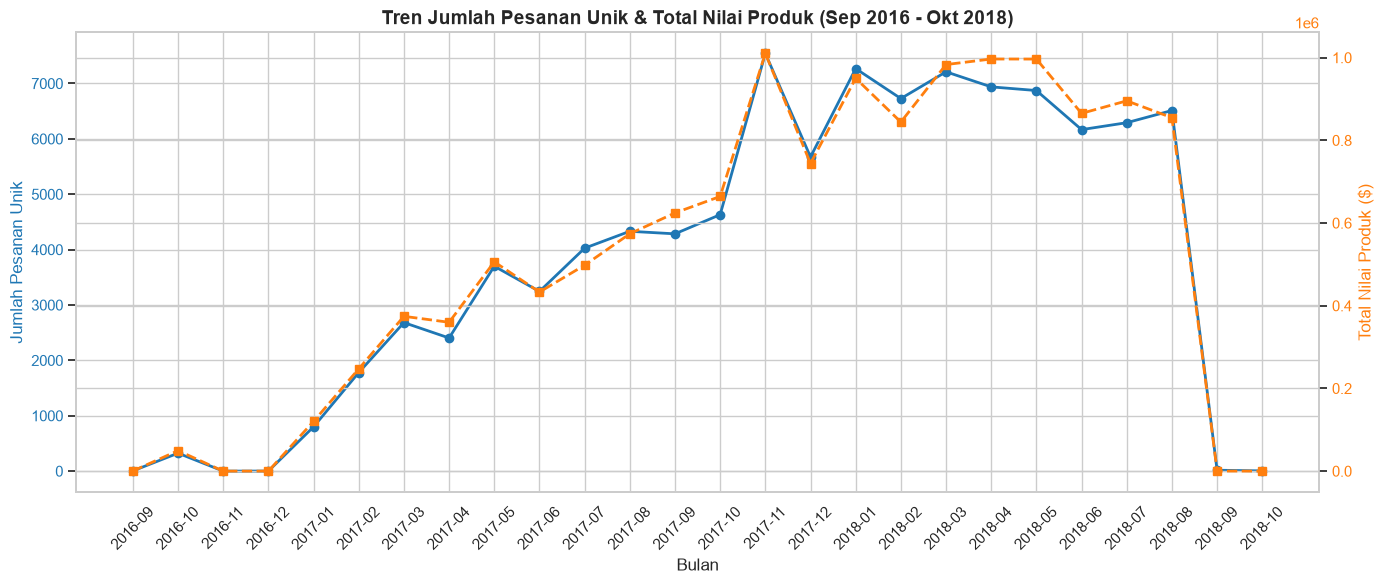

In [7]:
fig, ax1 = plt.subplots(figsize=(14, 6))

# Subplot 1: Total Pesanan Unik
color = 'tab:blue'
ax1.set_xlabel('Bulan', fontsize=12)
ax1.set_ylabel('Jumlah Pesanan Unik', color=color, fontsize=12)
ax1.plot(monthly_summary['year_month'], monthly_summary['total_orders'], marker='o', color=color, linewidth=2, label='Total Pesanan')
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=45)

# Subplot 2 (Sumbu Y Kedua): Total Nilai Produk
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Total Nilai Produk ($)', color=color, fontsize=12)
ax2.plot(monthly_summary['year_month'], monthly_summary['total_revenue'], marker='s', color=color, linewidth=2, linestyle='--', label='Total Revenue')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Tren Jumlah Pesanan Unik & Total Nilai Produk (Sep 2016 - Okt 2018)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

### Pertanyaan 2: Ketepatan Pengiriman dan Ulasan Pelanggan

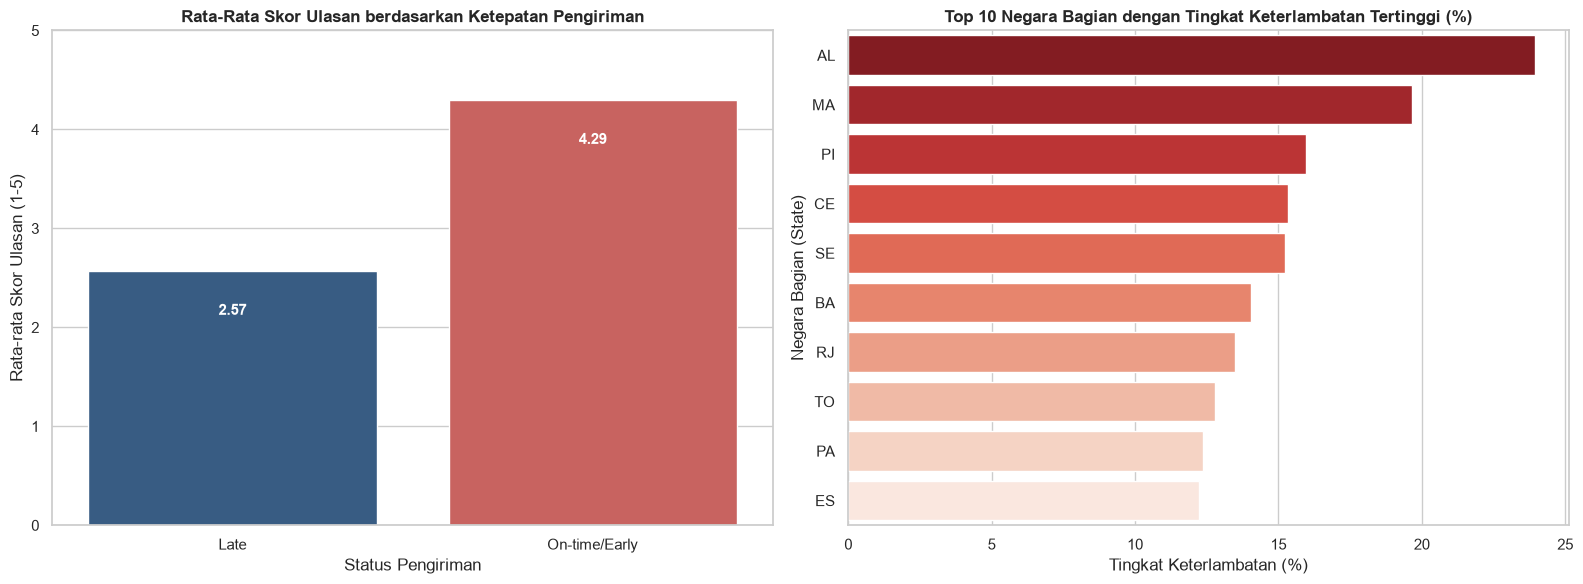

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Grafik 1: Perbedaan Skor Ulasan (dengan parameter hue dan legend=False untuk menghindari warning)
sns.barplot(x='delivery_status', y='review_score', data=review_by_status, hue='delivery_status', palette=['#2b5c8f', '#d9534f'], legend=False, ax=ax[0])
ax[0].set_title('Rata-Rata Skor Ulasan berdasarkan Ketepatan Pengiriman', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Status Pengiriman')
ax[0].set_ylabel('Rata-rata Skor Ulasan (1-5)')
ax[0].set_ylim(0, 5)
for p in ax[0].patches:
    ax[0].annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2., p.get_height() - 0.4),
                   ha='center', va='center', fontsize=11, color='white', fontweight='bold')

# Grafik 2: Top 10 Negara Bagian dengan Keterlambatan Tertinggi (Minimal 100 Pesanan)
sns.barplot(x='late_rate', y='customer_state', data=state_filtered.head(10), hue='customer_state', palette='Reds_r', legend=False, ax=ax[1])
ax[1].set_title('Top 10 Negara Bagian dengan Tingkat Keterlambatan Tertinggi (%)', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Tingkat Keterlambatan (%)')
ax[1].set_ylabel('Negara Bagian (State)')

plt.tight_layout()
plt.show()

## 5. Analisis Lanjutan (RFM Analysis)

In [9]:
# Menentukan tanggal acuan untuk Recency (hari setelah pesanan terakhir)
recent_date = orders_clean_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# Menggabungkan data pesanan dengan customer_unique_id & price
rfm_df = pd.merge(orders_clean_df, order_items_sum, on='order_id', how='inner')
rfm_df = pd.merge(rfm_df, customers_df[['customer_id', 'customer_unique_id']], on='customer_id', how='inner')

# Perhitungan RFM
rfm = rfm_df.groupby('customer_unique_id').agg(
    Recency=('order_purchase_timestamp', lambda x: (recent_date - x.max()).days),
    Frequency=('order_id', 'nunique'),
    Monetary=('price', 'sum')
).reset_index()

print("=== RINGKASAN STATISTIK RFM ===")
print(rfm.describe())

=== RINGKASAN STATISTIK RFM ===
            Recency     Frequency      Monetary
count  93350.000000  93350.000000  93350.000000
mean     237.950070      1.033423    141.620235
std      152.589932      0.209106    215.702028
min        1.000000      1.000000      0.850000
25%      114.000000      1.000000     47.650000
50%      219.000000      1.000000     89.700000
75%      346.000000      1.000000    154.697500
max      714.000000     15.000000  13440.000000


## 6. Conclusion & Recommendation

### Kesimpulan Pertanyaan 1 — Tren Transaksi Bulanan

Pada periode **September 2016–Oktober 2018**, jumlah pesanan dan total nilai produk sama-sama mencapai puncak pada **November 2017**, dengan **7.544 pesanan unik** dan nilai produk sebesar **R\$ 1.010.271,37**.

Bulan dengan jumlah pesanan paling sedikit adalah **November 2016**, ketika tidak ada pesanan yang tercatat. Nilai produk terendah adalah **R\$ 0**, yang tercatat pada November 2016 dan Oktober 2018. Pada Oktober 2018 terdapat empat pesanan, tetapi tidak ada nilai item produk yang tercatat.

Perhitungan jumlah pesanan mencakup semua status pesanan dalam periode tersebut, sedangkan total nilai produk dihitung berdasarkan penjumlahan harga item.

### Kesimpulan Pertanyaan 2 — Pengiriman dan Ulasan Pelanggan

Rata-rata skor ulasan untuk pesanan **terlambat adalah 2,57 dari 5**, sedangkan pesanan **tepat waktu atau lebih cepat memperoleh rata-rata 4,29 dari 5**. Dengan demikian, skor ulasan pada kelompok pesanan terlambat lebih rendah sekitar **1,73 poin**.

Di antara negara bagian dengan minimal 100 pesanan dan data tanggal pengiriman yang lengkap, **Alagoas (AL)** memiliki tingkat keterlambatan tertinggi, yaitu **23,93% (95 dari 397 pesanan)**.

### Rekomendasi

1. **Prioritaskan evaluasi pengiriman di Alagoas.** Telusuri kendala kurir, rute pengiriman, dan proses distribusi untuk mengidentifikasi faktor yang berkontribusi terhadap keterlambatan.
2. **Pantau pengalaman pelanggan.** Bandingkan skor ulasan dan tingkat keterlambatan secara berkala untuk mengevaluasi dampak perbaikan layanan pengiriman.
3. **Tinjau estimasi tanggal tiba.** Gunakan data waktu pengiriman aktual sebagai dasar untuk menghasilkan estimasi yang lebih realistis dan mengelola ekspektasi pelanggan.

Secara keseluruhan, temuan ini menunjukkan adanya hubungan antara keterlambatan pengiriman dan skor ulasan pelanggan yang lebih rendah. Namun, hubungan tersebut tidak serta-merta membuktikan bahwa keterlambatan merupakan satu-satunya faktor yang memengaruhi kepuasan pelanggan.